In [94]:
import jax_sn as jsn
%load_ext autoreload
%autoreload 2
import jax_sbgeom

import jax.numpy as jnp
import numpy as onp
from typing import Tuple
import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)

import pyvista as pv

def remove_zeros(array):
    a = onp.array(array)
    a[onp.abs(a) < 1e-14] = 0.0
    return a

from jax_sn.domain.geometric_domain import GeometricDomain, TopologicalSortedAngle
from jax_sn.solution_domain.solution_domain import FEMMatrices, PrecomputedGeometricData
from jax_sn.domain.geometric_domain import CrossSectionData, CrossSectionDataSingleGroup
from jax_sn.source import Source
from jax_sn.operators.transport_operator import TransportOperatorBatched, TransportOperatorMultipleAnglesVmap, TransportOperatorVmap, TransportOperatorBatchedPallas
from jax_sn.operators.mass_operator import MassOperator
from jax_sn.operators.moment_operator import MomentOperator

from typing import List
from jax_sn.tools.mesh_tools import _pad_last_dimension
import matplotlib.pyplot as plt
from dataclasses import dataclass
onp.set_printoptions(linewidth = 200)
from finite_elements.test_moment_scatter_operator import _setup_all_sb

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [95]:
from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex
from jax_sn.solution_domain import SolutionDomain
from jax_sn.domain import CrossSectionData, Domain
from jax_sn.source import Source

In [96]:
from finite_elements.test_anisotropic_scattering import _setup_anisotropic_scattering_args
dim = 3
degree = 2
n_elem_regions = [6, 3, 76, 6, 3, 3, 3]
print(sum(n_elem_regions))
d_other_dim = 5.0
n_other_dim = 10
tn_order = 3
args_ani = (dim, degree, n_elem_regions, d_other_dim, n_other_dim, tn_order)

Aop, source_total, solution_domain = _setup_anisotropic_scattering_args(dim, degree, n_elem_regions, d_other_dim, n_other_dim, tn_order)

Aop.transport_operator.solution_domain_data.domain.n_elements

100


60000

In [97]:
from jax_sn.tools.memory_analysis import OperatorAnalysis
from jax_sn.operators.single_group_operator import SingleGroupOperator

In [98]:
batched_top = TransportOperatorMultipleAnglesVmap(TransportOperatorBatchedPallas(Aop.transport_operator.solution_domain_data, Aop.transport_operator.topological_sorted_angle, 0, batch_size=100))

In [99]:
Aop_new = SingleGroupOperator(Aop.moment_operator, batched_top, Aop.mass_operator, Aop.scatter_operator)

In [102]:
print("Transport operator inv:")
print("\t", OperatorAnalysis.analyze_memory(batched_top,"inv"))
print("Mass operator:")
print("\t", OperatorAnalysis.analyze_memory(Aop.mass_operator,"mv"))
print("Moment operator:")
print("\t", OperatorAnalysis.analyze_memory(Aop.moment_operator, "mv"))
print("Scatter operator:")
print("\t", OperatorAnalysis.analyze_memory(Aop.scatter_operator,"mv"))
print("Total A operator")
print("\t", OperatorAnalysis.analyze_memory(Aop_new, "mv"))

Transport operator inv:
	 {'peak': 1296.950340270996, 'argument': 419.67293548583984, 'output': 329.5898666381836, 'temp': 547.691291809082}
Mass operator:
	 {'peak': 993.2280883789062, 'argument': 330.0483703613281, 'output': 329.5898666381836, 'temp': 333.59033203125}
Moment operator:
	 {'peak': 351.9026184082031, 'argument': 329.592041015625, 'output': 18.310569763183594, 'temp': 4.00048828125}
Scatter operator:
	 {'peak': 370.67137145996094, 'argument': 18.77093505859375, 'output': 329.5898666381836, 'temp': 22.31103515625}
Total A operator
	 {'peak': 1314.148780822754, 'argument': 109.31475067138672, 'output': 18.310569763183594, 'temp': 1186.527473449707}


In [107]:
rhs = Aop_new.moment_operator.mv(Aop_new.transport_operator.inv(Aop_new.mass_operator.mv(source_total)))

In [110]:
import lineax as lx

bicgstab_solver = lx.BiCGStab(1e-10, 1e-10, max_steps = 20)

In [112]:
solution = lx.linear_solve(Aop_new, rhs, bicgstab_solver)

In [114]:
solution.stats

{'max_steps': 20, 'num_steps': Array(12, dtype=int64)}

In [119]:
solver_state = solution.value

(4, 60000, 10)

In [132]:
x = jnp.linspace(0, 1.3, 1000)
y = jnp.full_like(x, d_other_dim * 0.5 )
z = jnp.full_like(x, d_other_dim * 0.5 )
xyz = jnp.stack([x, y, z], axis=-1)

interps = solution_domain.interpolate(xyz, solution.value[0])

In [128]:
from finite_elements.test_anisotropic_scattering import _get_expected_values_sb

In [131]:
sb_values = _get_expected_values_sb(*args_ani)

BiCGSTAB completed after 14 iterations with final error: 3.89956e-21


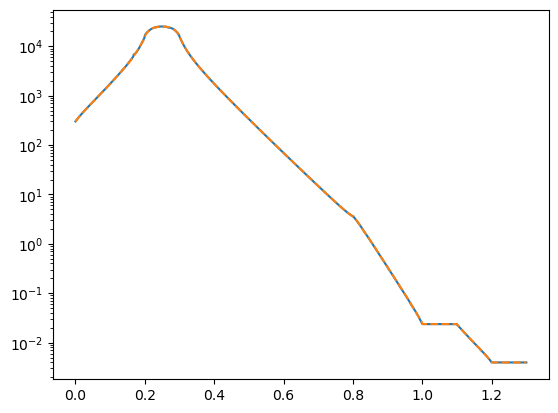

In [136]:
plt.semilogy(x, interps) 

plt.semilogy(x, sb_values, '--')

In [103]:
print("Transport operator inv:")
print("\t", OperatorAnalysis.analyze_timing(batched_top,"inv", n_samples = 10, ignore_n=2))
print("Mass operator:")
print("\t", OperatorAnalysis.analyze_timing(Aop.mass_operator,"mv", n_samples = 10, ignore_n=2))
print("Moment operator:")
print("\t", OperatorAnalysis.analyze_timing(Aop.moment_operator, "mv", n_samples = 10, ignore_n=2))
print("Scatter operator:")
print("\t", OperatorAnalysis.analyze_timing(Aop.scatter_operator,"mv", n_samples = 10, ignore_n=2))
print("Total A operator")
print("\t", OperatorAnalysis.analyze_timing(Aop_new, "mv", n_samples = 10, ignore_n=2))

Transport operator inv:
	 0.810917317867279
Mass operator:
	 0.01631864905357361
Moment operator:
	 0.008447527885437012
Scatter operator:
	 0.0039528608322143555
Total A operator
	 0.832802951335907
